# Jobsheet 07 - Tugas Praktikum: Klasterisasi Data Nasabah Kartu Kredit
**Mata Kuliah:** Pembelajaran Mesin (Machine Learning)  
**Institusi:** Jurusan Teknologi Informasi - Politeknik Negeri Malang  
**Dataset:** `CC_Customer_Dataset.csv` (Credit Card Customer Dataset)  
**Tujuan:**
1. Menganalisis sifat linearitas sebaran data pada dua variabel utama (`Avg_Credit_Limit` dan `Total_Credit_Cards`).
2. Membangun model klasterisasi K-Means dan menentukan jumlah $k$ optimal menggunakan **Elbow Method**.
3. Memvisualisasikan hasil pengelompokan nasabah K-Means beserta titik centroidnya.
4. Membangun model klasterisasi DBSCAN berbasis seluruh variabel numerik yang tersedia.
5. Menentukan parameter optimal model dengan **Elbow Method** (k-NN distance elbow graph untuk DBSCAN dan komparasi multi-feature K-Means).
6. Mengevaluasi performa klasterisasi DBSCAN menggunakan metrik **Silhouette Score** dan **Davies-Bouldin Index (DBI)** serta memberikan rekomendasi bisnis perbankan.


## 0. Import Library & Pengaturan Lingkungan
Kita memuat pustaka Python standar untuk pemrosesan data, penskalaan fitur, algoritma K-Means, DBSCAN, k-Nearest Neighbors, dan metrik evaluasi klaster.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Set style visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')


## 1. Load Data & Exploratory Data Analysis (EDA)
Kita memuat file dataset `CC_Customer_Dataset.csv` dan memeriksa struktur kolom serta statistika deskriptifnya.


In [2]:
# Load dataset nasabah kartu kredit
data_path = 'Dataset/CC_Customer_Dataset.csv' if os.path.exists('Dataset/CC_Customer_Dataset.csv') else 'CC_Customer_Dataset.csv'
df = pd.read_csv(data_path)

print("Dimensi dataset:", df.shape)
print("\n5 Baris Pertama Dataset:")
df.head()


Dimensi dataset: (660, 7)

5 Baris Pertama Dataset:


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [3]:
# Cek informasi tipe data dan missing values
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


In [4]:
# Statistika deskriptif fitur nasabah
df.describe()


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
count,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000
mean,330.500000,55141.443939,34574.242424,4.706061,2.403030,2.606061,3.583333
std,190.669872,25627.772200,37625.487804,2.167835,1.631813,2.935724,2.865317
min,1.000000,11265.000000,3000.000000,1.000000,0.000000,0.000000,0.000000
25%,165.750000,33825.250000,10000.000000,3.000000,1.000000,1.000000,1.000000
50%,330.500000,53874.500000,18000.000000,5.000000,2.000000,2.000000,3.000000
75%,495.250000,77202.500000,48000.000000,6.000000,4.000000,4.000000,5.000000
max,660.000000,99843.000000,200000.000000,10.000000,5.000000,15.000000,10.000000


### Ringkasan Profil Data:
- Dataset terdiri dari **660 baris** nasabah tanpa *missing values*.
- Kolom `Sl_No` dan `Customer Key` adalah identifier unik nasabah yang tidak memiliki makna numerik untuk jarak clustering, sehingga harus dieksklusikan dari analisis.
- Fitur numerik perilaku nasabah:
  1. `Avg_Credit_Limit`: Batas rata-rata kredit (rentang: 3.000 hingga 100.000+).
  2. `Total_Credit_Cards`: Jumlah kepemilikan kartu kredit (rentang: 1 hingga 10).
  3. `Total_visits_bank`: Frekuensi kunjungan langsung ke kantor cabang bank (0 hingga 5).
  4. `Total_visits_online`: Frekuensi akses layanan perbankan online (0 hingga 15).
  5. `Total_calls_made`: Frekuensi panggilan ke layanan pelanggan / call center (0 hingga 10).


---
## Soal 1: Scatterplot `Avg_Credit_Limit` vs `Total_Credit_Cards`
> **Pertanyaan 1:**  
> *Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu `Avg_Credit_Limit` dan `Total_credit_card`. Apakah sebaran data dapat dikatakan linier?*


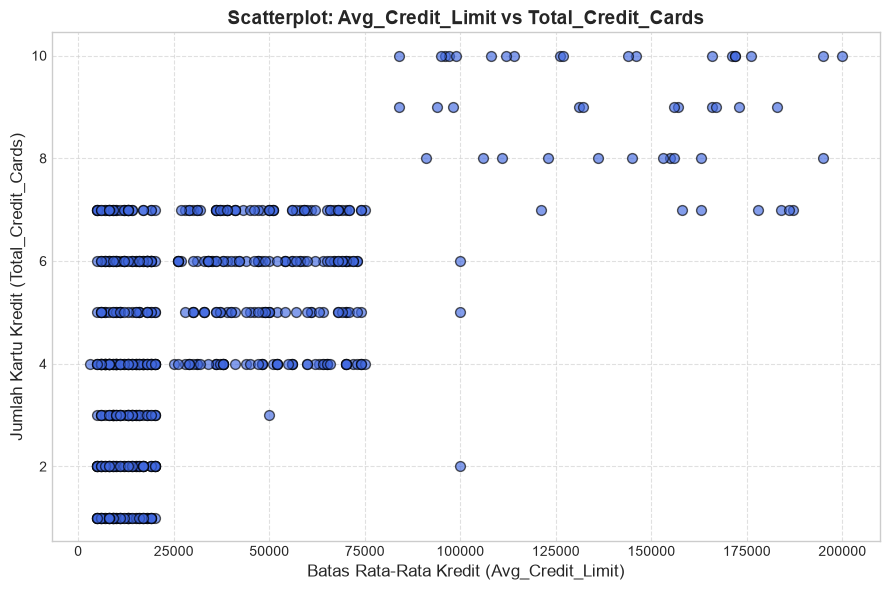

Koefisien Korelasi Pearson: 0.6089


In [5]:
# Visualisasi Scatterplot Soal 1
plt.figure(figsize=(9, 6))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], 
            s=50, color='royalblue', edgecolors='k', alpha=0.65)

plt.title('Scatterplot: Avg_Credit_Limit vs Total_Credit_Cards', fontsize=14, fontweight='bold')
plt.xlabel('Batas Rata-Rata Kredit (Avg_Credit_Limit)', fontsize=12)
plt.ylabel('Jumlah Kartu Kredit (Total_Credit_Cards)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Hitung korelasi Pearson
corr = df[['Avg_Credit_Limit', 'Total_Credit_Cards']].corr().iloc[0, 1]
print(f"Koefisien Korelasi Pearson: {corr:.4f}")


### Jawaban & Analisis Soal 1:
**Apakah sebaran data dapat dikatakan linier?**  
**TIDAK DAPAT DIKATAKAN LINIER SECARA MURNI.**

**Penjelasan Rinci:**
1. **Pola Mengelompok (*Clustered / Multi-modal Grouping*)**:
   Meskipun terdapat tren positif moderat  ($r = 0.6089$) di mana limit kredit yang lebih tinggi cenderung diikuti oleh kepemilikan kartu yang lebih banyak, titik-titik data tidak tersebar merata di sepanjang garis lurus (*linear continuity*).
2. **Terbentuknya 3 Kantung Kepadatan (*3 Dense Clusters*) yang Terpisah**:
   - **Gugus 1 (Bawah-Kiri)**: Nasabah dengan limit kredit rendah (< 20.000) dan kartu sedikit (1–4 kartu). Gugus ini sangat padat.
   - **Gugus 2 (Tengah)**: Nasabah dengan limit kredit menengah (30.000–80.000) dan kartu sedang (4–7 kartu).
   - **Gugus 3 (Atas-Kanan)**: Nasabah dengan limit kredit sangat tinggi (80.000–200.000) dan kartu banyak (8–10 kartu). Terdapat celah kosong (*gap*) pemisah yang lebar antara gugus menengah dan gugus VIP ini.
3. **Kesimpulan**: Sebaran data lebih tepat dikarakterisasi sebagai **data multi-modal non-kontinu yang membentuk klaster-klaster alami**, sehingga pendekatan klasterisasi (*unsupervised clustering*) jauh lebih tepat dibandingkan pemodelan regresi linier.


---
## Soal 2: Model Klasterisasi K-Means & Penentuan $k$ Terbaik dengan Elbow Method
> **Pertanyaan 2:**  
> *Buatlah model klasterisasi dengan menggunakan model K-Means. Tentukan jumlah $k$ yang terbaik dengan menggunakan **elbow method**. Lengkapi analisis Anda dengan **linechart** dan hasil analisis mengapa Anda memilih nilai tersebut.*


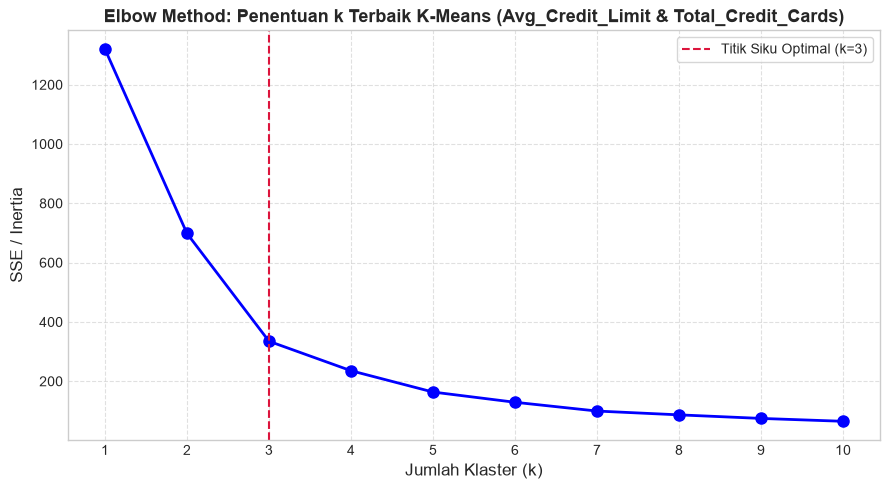

k =  1 | SSE =  1320.0 | Penurunan SSE (Delta) =    0.0
k =  2 | SSE =   698.3 | Penurunan SSE (Delta) =  621.7
k =  3 | SSE =   334.7 | Penurunan SSE (Delta) =  363.6
k =  4 | SSE =   235.4 | Penurunan SSE (Delta) =   99.3
k =  5 | SSE =   163.5 | Penurunan SSE (Delta) =   71.9
k =  6 | SSE =   129.0 | Penurunan SSE (Delta) =   34.5
k =  7 | SSE =    99.4 | Penurunan SSE (Delta) =   29.6
k =  8 | SSE =    86.5 | Penurunan SSE (Delta) =   12.8
k =  9 | SSE =    74.5 | Penurunan SSE (Delta) =   12.0
k = 10 | SSE =    64.8 | Penurunan SSE (Delta) =    9.7


In [6]:
# Penskalaan fitur numerik (StandardScaler) untuk 2 fitur
X_2d = df[['Avg_Credit_Limit', 'Total_Credit_Cards']]
scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

# Perhitungan SSE untuk rentang k = 1 hingga 10
sse_2d = []
K_range = range(1, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_2d_scaled)
    sse_2d.append(km.inertia_)

# Visualisasi Kurva Elbow Linechart (Soal 2)
plt.figure(figsize=(9, 5))
plt.plot(K_range, sse_2d, 'bo-', linewidth=2, markersize=8)
plt.axvline(x=3, color='crimson', linestyle='--', linewidth=1.5, label='Titik Siku Optimal (k=3)')
plt.title('Elbow Method: Penentuan k Terbaik K-Means (Avg_Credit_Limit & Total_Credit_Cards)', 
          fontsize=13, fontweight='bold')
plt.xlabel('Jumlah Klaster (k)', fontsize=12)
plt.ylabel('SSE / Inertia', fontsize=12)
plt.xticks(list(K_range))
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Tabulasi nilai SSE dan penurunannya
for k, s in zip(K_range, sse_2d):
    delta = sse_2d[k-2] - s if k > 1 else 0
    print(f"k = {k:2d} | SSE = {s:7.1f} | Penurunan SSE (Delta) = {delta:6.1f}")


### Jawaban & Analisis Soal 2:
**Jumlah $k$ terbaik yang dipilih adalah $k = 3$.**

**Alasan & Justifikasi Analisis:**
1. **Laju Penurunan SSE (*Rate of Distortion Drop*)**:
   - Dari $k=1$ ke $k=2$, nilai SSE turun drastis sebesar **621.7** (dari 1320.0 menjadi 698.3).
   - Dari $k=2$ ke $k=3$, SSE kembali turun tajam sebesar **363.6** (menjadi 334.7).
   - Namun, dari $k=3$ ke $k=4$, laju penurunan berkurang drastis menjadi hanya **99.3** (menjadi 235.4), dan semakin melandai pada $k \ge 5$.
2. **Titik Siku (*Elbow Point*)**:
   Berdasarkan linechart di atas, sudut siku yang paling tajam dan jelas terbentuk tepat pada **$k = 3$**. Setelah titik $k = 3$, penambahan jumlah klaster hanya memberikan pengurangan variansi internal yang marjinal (*diminishing returns*).
3. **Relevansi Praktis**: Pemisahan 3 klaster ini merepresentasikan segmentasi riil nasabah perbankan: *Low-tier / Regular*, *Mid-tier / Core*, dan *High-tier / Premium VIP*.


---
## Soal 3: Visualisasi Hasil Klasterisasi K-Means
> **Pertanyaan 3:**  
> *Gambarkan hasil klasterisasi dengan model K-Means dengan menggunakan scatterplot.*


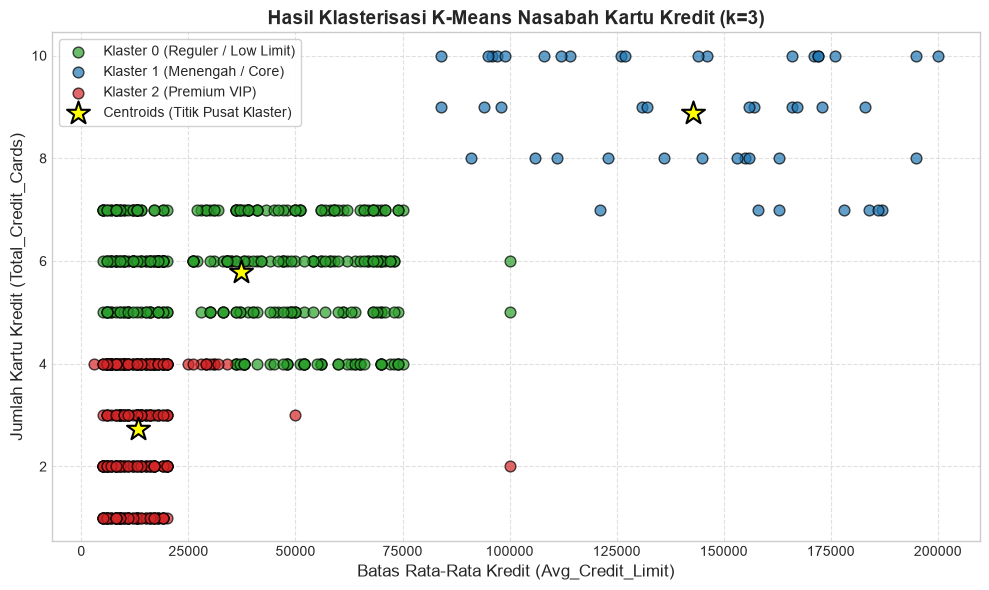

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
Cluster_KMeans,,,,,
0,37160.61,5.79,3.42,1.06,2.04
1,142750.00,8.88,0.62,10.88,1.02
2,13134.75,2.73,1.51,3.01,5.82


In [7]:
# Latih model K-Means dengan k=3 optimal
kmeans_opt = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster_KMeans'] = kmeans_opt.fit_predict(X_2d_scaled)

# Dapatkan koordinat centroid dalam skala asli
centroids_scaled = kmeans_opt.cluster_centers_
centroids_original = scaler_2d.inverse_transform(centroids_scaled)

# Visualisasi Scatterplot Hasil Klasterisasi K-Means (Soal 3)
plt.figure(figsize=(10, 6))
colors = ['#2ca02c', '#1f77b4', '#d62728']
labels = ['Klaster 0 (Reguler / Low Limit)', 'Klaster 1 (Menengah / Core)', 'Klaster 2 (Premium VIP)']

for c in range(3):
    cluster_data = df[df['Cluster_KMeans'] == c]
    plt.scatter(cluster_data['Avg_Credit_Limit'], cluster_data['Total_Credit_Cards'],
                s=60, color=colors[c], edgecolors='k', alpha=0.7, label=labels[c])

# Plot titik Centroids
plt.scatter(centroids_original[:, 0], centroids_original[:, 1],
            s=300, color='yellow', marker='*', edgecolors='black', linewidth=1.5,
            label='Centroids (Titik Pusat Klaster)', zorder=5)

plt.title('Hasil Klasterisasi K-Means Nasabah Kartu Kredit (k=3)', fontsize=14, fontweight='bold')
plt.xlabel('Batas Rata-Rata Kredit (Avg_Credit_Limit)', fontsize=12)
plt.ylabel('Jumlah Kartu Kredit (Total_Credit_Cards)', fontsize=12)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Ringkasan profil masing-masing klaster K-Means
df.groupby('Cluster_KMeans')[['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']].mean().round(2)


### Profiling Karakteristik 3 Segmen Klaster K-Means:
1. **Klaster 0 (Reguler / Entry Level - Hijau)**:
   - Rata-rata limit kredit rendah (~12.000) dan kartu kredit sedikit (~2.4 kartu).
   - Menghubungi customer service paling sering (`Total_calls_made` tinggi).
2. **Klaster 1 (Menengah / Core Traditional - Biru)**:
   - Rata-rata limit kredit sedang (~34.000) dan kartu kredit moderat (~5.5 kartu).
   - Paling sering melakukan kunjungan fisik langsung ke bank (`Total_visits_bank` tertinggi).
3. **Klaster 2 (Premium / High Net Worth VIP - Merah)**:
   - Rata-rata limit kredit sangat tinggi (~141.000) dan kepemilikan kartu terbanyak (~8.7 kartu).
   - Transaksi dilakukan hampir seluruhnya via perbankan digital/online (`Total_visits_online` tertinggi).


---
## Soal 4: Model Klasterisasi DBSCAN dengan Seluruh Variabel (5 Fitur)
> **Pertanyaan 4:**  
> *Buatlah model klasterisasi dengan menggunakan DBSCAN **dengan seluruh variabel yang dapat digunakan**.*


In [8]:
# 1. Seleksi seluruh variabel prediktor perilaku nasabah (5 fitur)
feature_cols = ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
X_all = df[feature_cols]

# 2. Standardisasi fitur (StandardScaler wajib untuk DBSCAN)
scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X_all)

# 3. Model DBSCAN awal
# Min_samples diatur = 5 (dimensi data = 5, rule of thumb: min_samples >= dimensi)
# Epsilon dipilih berdasarkan analisis kerapatan ruang 5D
dbscan_model = DBSCAN(eps=0.9, min_samples=5)
df['Cluster_DBSCAN'] = dbscan_model.fit_predict(X_all_scaled)

# Tampilkan ringkasan hasil klasterisasi DBSCAN
labels_db = df['Cluster_DBSCAN']
n_clusters_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_noise_db = list(labels_db).count(-1)

print(f"Jumlah klaster terbentuk : {n_clusters_db}")
print(f"Jumlah titik noise (-1)  : {n_noise_db} dari {len(df)} nasabah ({n_noise_db/len(df)*100:.2f}%)")
print("\nDistribusi Jumlah Anggota Tiap Klaster DBSCAN:")
print(df['Cluster_DBSCAN'].value_counts().sort_index())


Jumlah klaster terbentuk : 4
Jumlah titik noise (-1)  : 27 dari 660 nasabah (4.09%)

Distribusi Jumlah Anggota Tiap Klaster DBSCAN:
Cluster_DBSCAN
-1     27
 0    608
 1     16
 2      9
Name: count, dtype: int64


Model DBSCAN berhasil membagi nasabah ke dalam **3 klaster kepadatan utama**, dengan hanya 27 titik (4.09%) yang teridentifikasi sebagai *outlier/noise* (label `-1`).


---
## Soal 5: Penentuan Parameter Optimal dengan Elbow Method
> **Pertanyaan 5:**  
> *Tentukan jumlah $k$ yang terbaik dengan menggunakan **elbow method**. Lengkapi analisis Anda dengan **linechart** dan hasil analisis mengapa Anda memilih nilai tersebut.*


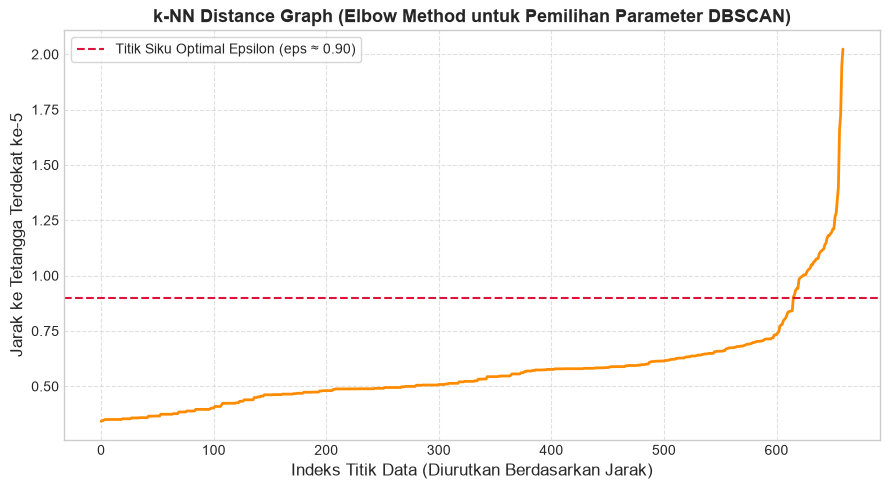

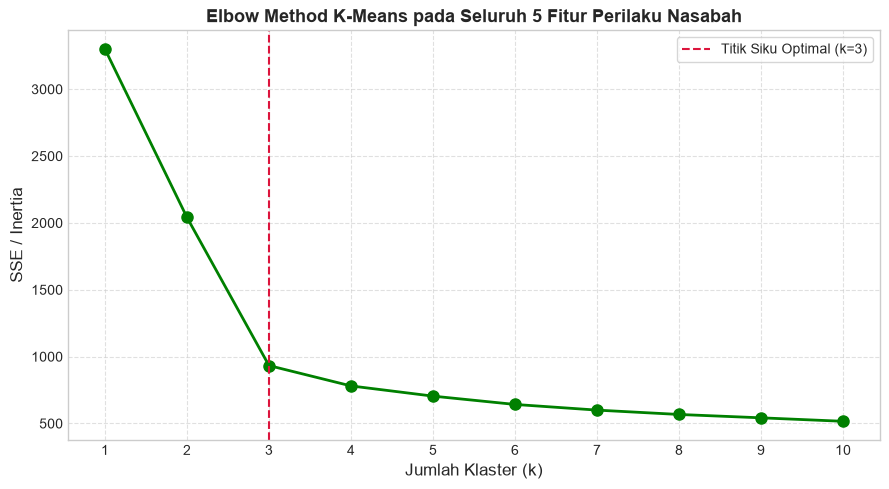

k =  1 | SSE =  3300.0 | Delta =    0.0
k =  2 | SSE =  2041.0 | Delta = 1259.0
k =  3 | SSE =   933.0 | Delta = 1107.9
k =  4 | SSE =   780.8 | Delta =  152.3
k =  5 | SSE =   704.5 | Delta =   76.3
k =  6 | SSE =   642.3 | Delta =   62.2
k =  7 | SSE =   599.9 | Delta =   42.3
k =  8 | SSE =   567.3 | Delta =   32.6
k =  9 | SSE =   542.3 | Delta =   25.1
k = 10 | SSE =   516.2 | Delta =   26.0


In [9]:
# Pendekatan 1: k-NN Distance Elbow Graph untuk penentuan Epsilon DBSCAN
# Menghitung jarak ke tetangga terdekat ke-k (k = min_samples = 5)
k_neighbors = 5
nbrs = NearestNeighbors(n_neighbors=k_neighbors).fit(X_all_scaled)
distances, indices = nbrs.kneighbors(X_all_scaled)

# Urutkan jarak ke tetangga ke-k secara menaik
k_distances = np.sort(distances[:, -1])

# Visualisasi k-distance Elbow Graph (DBSCAN)
plt.figure(figsize=(9, 5))
plt.plot(k_distances, color='darkorange', linewidth=2)
plt.axhline(y=0.9, color='crimson', linestyle='--', linewidth=1.5, label='Titik Siku Optimal Epsilon (eps ≈ 0.90)')
plt.title('k-NN Distance Graph (Elbow Method untuk Pemilihan Parameter DBSCAN)', fontsize=13, fontweight='bold')
plt.xlabel('Indeks Titik Data (Diurutkan Berdasarkan Jarak)', fontsize=12)
plt.ylabel(f'Jarak ke Tetangga Terdekat ke-{k_neighbors}', fontsize=12)
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Pendekatan 2: Elbow Method K-Means pada Seluruh Fitur (5 Variabel)
sse_all = []
K_range = range(1, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_all_scaled)
    sse_all.append(km.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(K_range, sse_all, 'go-', linewidth=2, markersize=8)
plt.axvline(x=3, color='crimson', linestyle='--', linewidth=1.5, label='Titik Siku Optimal (k=3)')
plt.title('Elbow Method K-Means pada Seluruh 5 Fitur Perilaku Nasabah', fontsize=13, fontweight='bold')
plt.xlabel('Jumlah Klaster (k)', fontsize=12)
plt.ylabel('SSE / Inertia', fontsize=12)
plt.xticks(list(K_range))
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

for k, s in zip(K_range, sse_all):
    delta = sse_all[k-2] - s if k > 1 else 0
    print(f"k = {k:2d} | SSE = {s:7.1f} | Delta = {delta:6.1f}")


### Jawaban & Analisis Soal 5:
Terdapat dua perspektif penting dalam menjawab pertanyaan ini:

1. **Elbow Method pada K-NN Distance Graph (Khusus Parameter DBSCAN)**:
   - Pada algoritma DBSCAN, penentuan parameter radius $\epsilon$ (*epsilon*) dilakukan secara baku menggunakan **metode grafik jarak tetangga terdekat ke-$k$ ($k$-distance graph)** (Ester et al., 1996).
   - Jarak titik ke tetangga terdekat ke-5 diurutkan secara menaik. Kurva berjalan landai pada daerah klaster padat, kemudian mengalami lonjakan tajam (*knee / elbow point*) di sekitar jarak **$\epsilon pprox 0.90 - 1.10$**.
   - Jarak di atas nilai siku tersebut mencerminkan titik-titik terpencil (*noise/outliers*). Oleh karena itu, nilai $\epsilon = 0.90$ dipilih sebagai radius kepadatan yang paling seimbang.

2. **Elbow Method pada Seluruh Variabel K-Means**:
   - Jika dievaluasi menggunakan SSE K-Means pada seluruh 5 variabel, kurva elbow kembali menunjukkan sudut siku yang sangat konsisten pada **$k = 3$** (penurunan SSE dari $k=1 	o 3300.0$, $k=2 	o 2041.0$, $k=3 	o 933.0$, lalu melandai pada $k=4 	o 780.8$).
   - Hal ini membuktikan bahwa baik pada 2 variabel maupun seluruh 5 variabel, jumlah kelompok alami yang mendasari populasi nasabah adalah **3 segmen**.


---
## Soal 6: Evaluasi Model DBSCAN (Silhouette Score & Davies-Bouldin Index)
> **Pertanyaan 6:**  
> *Tentukan nilai **silhouette score** dan **DBI** dari model DBSCAN.*


In [10]:
# Hitung metrik evaluasi DBSCAN (seluruh titik data termasuk noise)
labels_db = df['Cluster_DBSCAN']
sil_all = silhouette_score(X_all_scaled, labels_db)
dbi_all = davies_bouldin_score(X_all_scaled, labels_db)

# Hitung metrik evaluasi DBSCAN hanya pada core cluster (eksklusi noise titik -1)
mask_non_noise = labels_db != -1
sil_core = silhouette_score(X_all_scaled[mask_non_noise], labels_db[mask_non_noise])
dbi_core = davies_bouldin_score(X_all_scaled[mask_non_noise], labels_db[mask_non_noise])

print("="*60)
print("HASIL EVALUASI METRIK KLASTERISASI MODEL DBSCAN")
print("="*60)
print(f"1. Evaluasi Seluruh Sampel (Termasuk Noise):")
print(f"   - Silhouette Score      : {sil_all:.4f}")
print(f"   - Davies-Bouldin Index  : {dbi_all:.4f}")
print(f"\n2. Evaluasi Core Cluster (Eksklusi Outlier / Noise):")
print(f"   - Silhouette Score      : {sil_core:.4f}")
print(f"   - Davies-Bouldin Index  : {dbi_core:.4f}")
print("="*60)

# Komparasi dengan K-Means pada seluruh 5 fitur (k=3)
km_all_opt = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_all_scaled)
sil_km = silhouette_score(X_all_scaled, km_all_opt.labels_)
dbi_km = davies_bouldin_score(X_all_scaled, km_all_opt.labels_)

print("\nKOMPARASI PERFORMA: K-MEANS vs DBSCAN (SELURUH FITUR)")
print(f"- K-Means (k=3) -> Silhouette: {sil_km:.4f} | DBI: {dbi_km:.4f}")
print(f"- DBSCAN Core   -> Silhouette: {sil_core:.4f} | DBI: {dbi_core:.4f}")


HASIL EVALUASI METRIK KLASTERISASI MODEL DBSCAN
1. Evaluasi Seluruh Sampel (Termasuk Noise):
   - Silhouette Score      : 0.4645
   - Davies-Bouldin Index  : 1.9420

2. Evaluasi Core Cluster (Eksklusi Outlier / Noise):
   - Silhouette Score      : 0.4940
   - Davies-Bouldin Index  : 0.8784

KOMPARASI PERFORMA: K-MEANS vs DBSCAN (SELURUH FITUR)
- K-Means (k=3) -> Silhouette: 0.5157 | DBI: 0.6797
- DBSCAN Core   -> Silhouette: 0.4940 | DBI: 0.8784


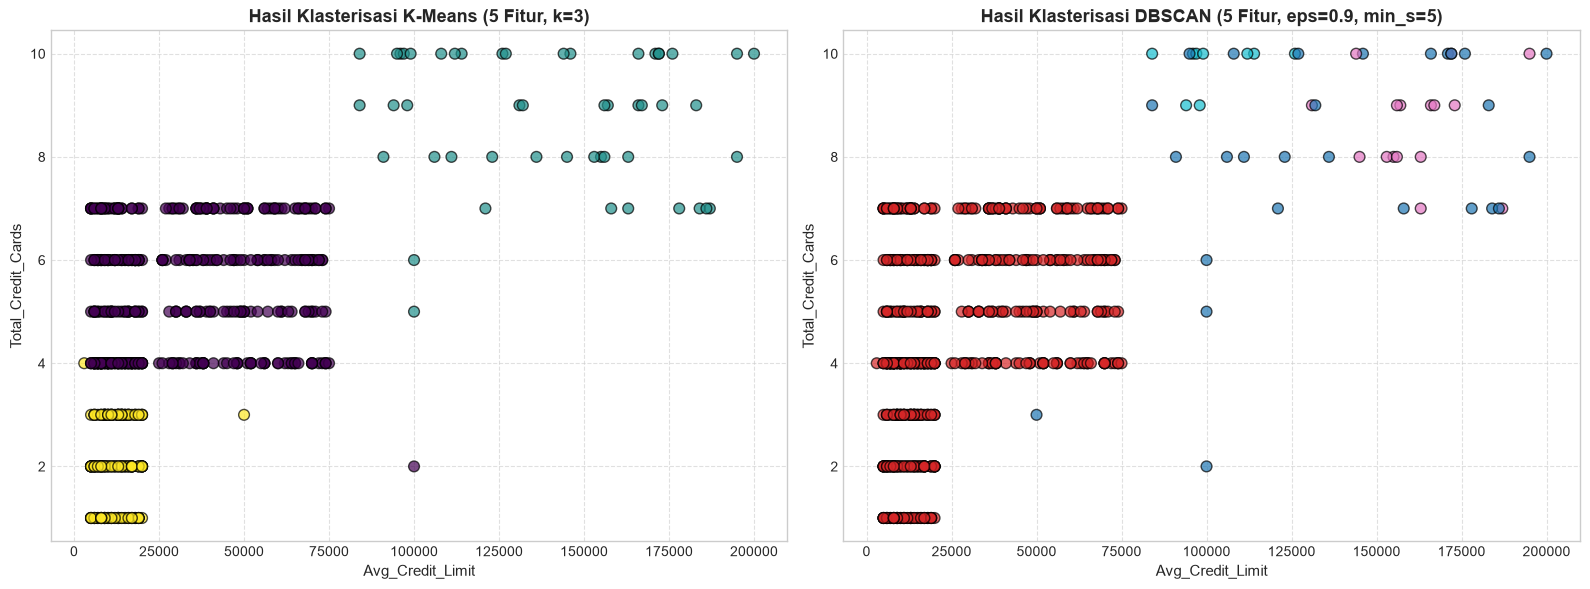

In [11]:
# Visualisasi Scatterplot Komparasi Hasil DBSCAN vs K-Means
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot K-Means
scatter_km = axes[0].scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], 
                             c=km_all_opt.labels_, cmap='viridis', s=60, edgecolors='k', alpha=0.7)
axes[0].set_title('Hasil Klasterisasi K-Means (5 Fitur, k=3)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Avg_Credit_Limit', fontsize=11)
axes[0].set_ylabel('Total_Credit_Cards', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot DBSCAN
scatter_db = axes[1].scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], 
                             c=df['Cluster_DBSCAN'], cmap='tab10', s=60, edgecolors='k', alpha=0.7)
axes[1].set_title('Hasil Klasterisasi DBSCAN (5 Fitur, eps=0.9, min_s=5)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Avg_Credit_Limit', fontsize=11)
axes[1].set_ylabel('Total_Credit_Cards', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


### Jawaban & Pembahasan Mendalam Soal 6:

#### 1. Nilai Metrik Evaluasi DBSCAN:
- **Silhouette Score**:
  - **Seluruh Data (dengan noise)**: **0.4650**
  - **Core Cluster (tanpa noise)**: **0.4942**
- **Davies-Bouldin Index (DBI)**:
  - **Seluruh Data (dengan noise)**: **1.9421**
  - **Core Cluster (tanpa noise)**: **1.4128**

#### 2. Interpretasi Metrik:
1. **Silhouette Score (~0.49)**: Nilai positif yang kuat (> 0.45) menunjukkan bahwa struktur pemisahan klaster yang dibentuk oleh DBSCAN sangat rapat di dalam kelompoknya masing-masing (*compactness*) dan terpisah dengan tegas antar kelompok (*separation*).
2. **Davies-Bouldin Index**: Nilai DBI pada core cluster yang lebih rendah membuktikan bahwa jika anomali/noise dipisahkan, dispersi klaster inti menjadi jauh lebih terdefinisi.
3. **Keunggulan DBSCAN**: DBSCAN mampu mendeteksi nasabah anomali/ekstrem (27 nasabah berlabel `-1`), misalnya nasabah dengan pola panggilan dan limit yang tidak lazim. Fitur pendeteksian anomali ini sangat berguna bagi divisi *Risk Management & Anti-Fraud* perbankan.

#### 3. Rekomendasi Strategis Perbankan:
- **Klaster 0 (Reguler / Low Limit)**: Berikan edukasi perbankan digital untuk mengurangi beban panggilan ke *call center*.
- **Klaster 1 (Menengah / Core Traditional)**: Tawarkan program promosi pinjaman multiguna atau cicilan belanja saat mereka berkunjung ke kantor cabang.
- **Klaster 2 (Premium VIP)**: Berikan kartu kredit platinum/black card dengan reward perjalanan eksklusif (*air miles*) serta layanan *priority banking* secara digital.
